# ¿Ayuda ver toda la ventana? Pooling temporal antes de la cabeza lineal

**Pregunta:** la cabeza de CPC-GRU sólo recibe `c_T`, el contexto de la GRU en el **último** de los 48 instantes de la ventana. ¿Clasifica mejor si recibe un resumen de **todos** los instantes `c_1 … c_T`?

El notebook 13 mostró que darle más capacidad a la cabeza (MLP) no mejora: el límite está en la información que le llega, no en la frontera de decisión. El pooling cambia **qué información** recibe la cabeza, no su tamaño.

**Tres formas de resumir la ventana**, todas con la **misma cabeza lineal** (LayerNorm(256) → Dropout(0.2) → Linear(256, 7)):

| Pooling | Qué recibe la cabeza | Parámetros extra |
|---|---|---|
| `ultimo` (notebook 11) | `c_T` | 0 |
| `promedio` | la media de `c_1 … c_T` | 0 |
| `atencion` | `Σ a_t c_t`, con pesos `a_t = softmax_t(w · c_t + b)` aprendidos | 257 |

**Qué se espera de cada uno.** Cada ventana se etiqueta con la actividad de su **último instante**.

- **Promedio:** pesa igual los 48 instantes. En una ventana que cruza una transición, el resumen se parece a la actividad anterior. Además, la GRU empieza de cero en cada ventana, así que los primeros `c_t` tienen poca historia.
- **Atención:** aprende dónde mirar. Puede concentrarse al final (y parecerse a `c_T`) o repartir el peso si eso separa mejor las clases.

**Diseño:** igual que el notebook 13.

- Subconjunto `EML` (10 variables).
- En cada ronda se cargan los pesos CPC del notebook 11 y sólo se repite el LP-FT. Las tres variantes parten del mismo encoder y la misma GRU.
- `ultimo` no se reentrena: se recargan los pesos finales del notebook 11 (control: deben reproducir sus predicciones).
- En la etapa LP se entrenan el pooling y la cabeza; en la etapa FT, toda la red. El pooling usa la tasa de aprendizaje de la cabeza.

**Análisis adicionales:** F1 en entrenamiento, F1 por clase, acierto en las ventanas que **cruzan una transición** (donde se esperaría que el pooling cambie algo) y dónde mira la atención dentro de la ventana.

**Tiempo estimado:** 12 rondas × 2 variantes ≈ 1–1.5 h. La atención es algo más lenta en la etapa LP, porque la secuencia `c_1 … c_T` se calcula en cada batch. Cada ronda se guarda al terminar y se carga si ya existe.

# 1. Configuración

In [1]:
import copy, json, os, re, time
import xml.etree.ElementTree as ET
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from scipy.interpolate import interp1d
from scipy.signal import butter, sosfiltfilt
from scipy.stats import wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------- Datos y validación (iguales al avance 5) -----------------------------
SEED = 0
TARGET_FS = 12                         # Hz
CV_SUBJECTS = tuple(range(1, 13))      # sujetos de la validación cruzada LOSO
TEST_SUBJECTS = (13, 14)               # reservados para la prueba final: no se usan aquí
WIN, SUP_HOP, CPC_HOP = 48, 6, 24      # ventana de 4 s; una ventana etiquetada cada 0.5 s y una sin etiqueta (CPC) cada 2 s
SCALER_FIT_POINTS = 250_000            # instantes que se muestrean para ajustar el escalador
PROBE_TRAIN_MAX = 15_000               # ventanas de la sonda que decide la parada temprana de CPC (como el notebook 10)

# ----------------------------- CPC-GRU + LP-FT (los valores de los notebooks 10 y 11) -----------------------------
CPC_EPOCHS, CPC_EVAL_EVERY, CPC_PATIENCE = 20, 2, 3
CPC_BATCH, CPC_LR, GRAD_CLIP, N_ANCHORS = 128, 5e-4, 1.0, 4
HORIZONS = tuple(range(1, 13))         # CPC predice de 1 a 12 pasos adelante (1 s)
FINETUNE_BATCH = 256
FINETUNE_LR_HEAD, FINETUNE_LR_BACKBONE = 1e-3, 1e-4
FT_EPOCHS, FT_PATIENCE = 30, 5         # etapa FT de LP-FT
LP_EPOCHS, LP_PATIENCE, LP_LR = 20, 3, 1e-3   # etapa LP de LP-FT
STEPS_CAP = FT_TRAIN_CAP = None        # límites sólo para la corrida de prueba

# ----------------------------- Formas de resumir la ventana -----------------------------
POOLINGS = ("ultimo", "promedio", "atencion")   # 'ultimo' = c_T, la referencia del notebook 11

# Corrida de prueba rápida (2 rondas, pocas épocas) para revisar que todo funciona: NB14_QUICK=1
QUICK = os.environ.get("NB14_QUICK") == "1"
FOLDS = CV_SUBJECTS
if QUICK:
    FOLDS = (1, 2)
    PROBE_TRAIN_MAX, FT_TRAIN_CAP, LP_EPOCHS, FT_EPOCHS = 2_000, 2_000, 1, 1

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SYNC_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}"                     # exportación MVNX sincronizada
RECOVER_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}_mvnx_recuperados"  # caché de los ensayos recuperados
MVNX_DIR, MVNX_LABEL_DIR = REPO_DIR / "datos_unzipped" / "mvnx_files", REPO_DIR / "datos_unzipped" / "Labels 2"
SAVED_DIR = REPO_DIR / "checkpoints" / f"cpc10_loso_mvnx_metodos_fs{TARGET_FS}"   # rondas del notebook 10 (30 variables)
NB11_DIR = REPO_DIR / "checkpoints" / f"nb11_variables_minimas_fs{TARGET_FS}"          # rondas del notebook 11
RUN_DIR = REPO_DIR / "checkpoints" / (f"nb14_pooling_fs{TARGET_FS}" + ("_quick" if QUICK else ""))
RUN_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = RUN_DIR / "progreso.log"
assert (SYNC_DIR / "metadata.json").exists(), f"Falta la exportación sincronizada en {SYNC_DIR.relative_to(REPO_DIR)}"
assert SAVED_DIR.exists(), f"Faltan las rondas del notebook 10 en {SAVED_DIR.relative_to(REPO_DIR)}"
assert (NB11_DIR / "gru_ft" / "EML").exists(), f"Faltan las rondas EML del notebook 11 en {NB11_DIR.relative_to(REPO_DIR)}"

SYNC_META = json.loads((SYNC_DIR / "metadata.json").read_text())
LABELS, NO_LABEL = SYNC_META["label_order"], SYNC_META["sin_etiqueta"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})


def log(message):
    """Imprime un mensaje con hora y lo guarda en progreso.log (útil para seguir corridas largas)."""
    line = f"{datetime.now():%Y-%m-%d %H:%M} | {message}"
    print(line)
    with open(LOG_FILE, "a") as fh:
        fh.write(line + "\n")


print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE} | rondas: {len(FOLDS)} | QUICK: {QUICK}")
print(f"Resultados en: {RUN_DIR.relative_to(REPO_DIR)}")

PyTorch 2.11.0 | dispositivo: mps | rondas: 12 | QUICK: False
Resultados en: checkpoints/nb14_pooling_fs12


# 2. Datos

Los mismos del notebook 11: MVNX a 12 Hz, las 30 variables de Xsens, etiqueta del instante final, ventanas de 4 s y los 3 ensayos recuperados del sujeto 7. No se construye la tabla del Random Forest.

In [2]:
# Columnas MVNX crudas que se necesitan para calcular las 30 variables
RAW_COLUMNS = (
    [f"position__{s}__{a}" for s in ("Pelvis", "Head", "LeftHand", "RightHand") for a in "xyz"]          # posiciones (m)
    + [f"velocity__{s}__{a}" for s in ("Pelvis", "LeftHand", "RightHand") for a in "xyz"]               # velocidades (m/s)
    + [f"angularVelocity__{s}__{a}" for s in ("Pelvis", "T8") for a in "xyz"]                            # giros (rad/s)
    + [f"jointAngle__{j}__c3" for j in ("jL5S1", "jC1Head", "jLeftElbow", "jRightElbow", "jLeftWrist", "jRightWrist",
                                       "jLeftHip", "jRightHip", "jLeftKnee", "jRightKnee")]               # flexiones (°)
    + [f"jointAngleXZY__{j}__{c}" for j in ("jLeftShoulder", "jRightShoulder") for c in ("c1", "c3")]   # hombros en XZY
    + [f"footContacts__{f}_{p}" for f in ("LeftFoot", "RightFoot") for p in ("Heel", "Toe")]            # contactos (0/1)
)
RAW_IDX = {c: i for i, c in enumerate(RAW_COLUMNS)}   # nombre de columna -> posición
SIDES = (("izq", "Left"), ("der", "Right"))           # prefijo en español y nombre del lado en el MVNX


def derive(raw):
    """Columnas MVNX crudas -> las 30 variables, con los lados fijos (izquierdo / derecho)."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    # --- Postura (14): ángulos articulares en grados ---
    out = {"tronco_flexion": col("jointAngle__jL5S1__c3"), "cuello_flexion": col("jointAngle__jC1Head__c3")}
    for lado, s in SIDES:
        out[f"{lado}_hombro_flexion"] = col(f"jointAngleXZY__j{s}Shoulder__c3")
        out[f"{lado}_hombro_abduccion"] = col(f"jointAngleXZY__j{s}Shoulder__c1")
        out[f"{lado}_codo_flexion"] = col(f"jointAngle__j{s}Elbow__c3")
        out[f"{lado}_muneca_flexion"] = col(f"jointAngle__j{s}Wrist__c3")
        out[f"{lado}_cadera_flexion"] = col(f"jointAngle__j{s}Hip__c3")
        out[f"{lado}_rodilla_flexion"] = col(f"jointAngle__j{s}Knee__c3")
    # --- Alturas y alcance (6): en metros; el alcance es la distancia horizontal mano–pelvis ---
    out["pelvis_altura"] = col("position__Pelvis__z")
    out["cabeza_altura"] = col("position__Head__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_altura"] = col(f"position__{s}Hand__z")
        out[f"{lado}_mano_alcance"] = np.hypot(col(f"position__{s}Hand__x") - col("position__Pelvis__x"),
                                               col(f"position__{s}Hand__y") - col("position__Pelvis__y"))
    # --- Velocidades (6): normas, para que no dependan de hacia dónde mira la persona ---
    out["pelvis_vel_horizontal"] = np.hypot(col("velocity__Pelvis__x"), col("velocity__Pelvis__y"))
    out["pelvis_vel_vertical"] = col("velocity__Pelvis__z")
    for lado, s in SIDES:
        out[f"{lado}_mano_rapidez"] = np.linalg.norm([col(f"velocity__{s}Hand__{a}") for a in "xyz"], axis=0)
    out["pelvis_giro"] = np.abs(col("angularVelocity__Pelvis__z"))
    out["tronco_vel_angular"] = np.linalg.norm([col(f"angularVelocity__T8__{a}") for a in "xyz"], axis=0)
    # --- Apoyo (4): contacto del talón y la punta de cada pie con el suelo ---
    for lado, s in SIDES:
        out[f"{lado}_talon"] = col(f"footContacts__{s}Foot_Heel")
        out[f"{lado}_punta"] = col(f"footContacts__{s}Foot_Toe")
    return np.column_stack(list(out.values())).astype(np.float32), list(out)


# Unidad y grupo de cada variable (se usan en tablas, en el escalador y en la gráfica de importancia)
def feature_unit(name):
    if name.endswith(("flexion", "abduccion")):
        return "°"
    if name.endswith(("altura", "alcance")):
        return "m"
    if name.endswith(("vel_horizontal", "vel_vertical", "rapidez")):
        return "m/s"
    if name.endswith(("giro", "vel_angular")):
        return "rad/s"
    return "0/1"

In [3]:
# Ensayos recuperados: los que la exportación excluyó SÓLO por la sEMG se leen del MVNX crudo, con los mismos
# controles de calidad del MVNX y el mismo remuestreo que la exportación.
EXCLUDED = pd.read_csv(SYNC_DIR / "exclusiones.csv")
SEMG_ONLY = EXCLUDED.groupby("mvnx_file")["motivo"].agg(lambda m: m.str.startswith("sEMG").all())   # excluido sólo por sEMG
RECOVER = sorted(SEMG_ONLY[SEMG_ONLY].index)
NS = "{http://www.xsens.com/mvn/mvnx}"                 # espacio de nombres del XML de Xsens
# Campos que se leen y cómo se remuestrea cada uno
FIELDS = {"position": "continua", "velocity": "continua", "angularVelocity": "continua",
          "jointAngle": "angulo", "jointAngleXZY": "angulo", "footContacts": "binaria"}
# Nombre de archivo -> sujeto, tarea, lado, carga y condición
MVNX_RE = re.compile(r"Subj_(?P<subject>\d+)_(?P<task>Isokin|MMH_Bim|MMH_One)_(?:(?P<side>[LR])_)?"
                     r"(?P<load_kg>\d+)kg_(?P<condition>St|\d+bpm|Trial_\d)\.mvnx")


def read_mvnx_fields(path):
    """Tiempos (s) y campos de FIELDS de los frames normales de un MVNX, con los nombres de su cabecera."""
    names = {"segment": [], "joint": [], "contactDefinition": []}
    times, raw = [], {}
    # El XML pesa cientos de MB: se lee por eventos y cada frame se borra después de leerlo
    with open(path, "rb") as fh:
        frames = None
        for event, el in ET.iterparse(fh, events=("start", "end")):
            tag = el.tag[len(NS):] if el.tag.startswith(NS) else el.tag
            if event == "start" and tag == "frames":
                frames = el
            elif event == "end" and tag in names and el.get("label") and frames is None:
                names[tag].append(el.get("label"))                     # nombres de segmentos, articulaciones y contactos
            elif event == "end" and tag == "frame":
                if el.get("type") == "normal":                         # se ignoran los frames de calibración
                    times.append(float(el.get("time")))
                    for c in el:
                        f = c.tag[len(NS):]
                        if f in FIELDS:
                            raw.setdefault(f, []).append(c.text or "")
                frames.remove(el)
    n = len(times)
    data = {k: np.array(" ".join(v).split(), dtype=np.float64).reshape(n, -1) for k, v in raw.items()}
    t = np.asarray(times) / 1000.0
    return t - t[0], data, names


# Nombres de columna de un campo, con el mismo formato que la exportación sincronizada
def mvnx_columns(field, names):
    if field in ("jointAngle", "jointAngleXZY"):
        return [f"{field}__{j}__c{c}" for j in names["joint"] for c in (1, 2, 3)]
    if field == "footContacts":
        return [f"{field}__{c}" for c in names["contactDefinition"]]
    return [f"{field}__{s}__{a}" for s in names["segment"] for a in "xyz"]


# Pasa-bajas antialias de fase cero (Butterworth de orden 4 a 4.8 Hz) antes de bajar de 240 a 12 Hz
def lowpass(x, fs):
    sos = butter(SYNC_META["antialias"]["orden"], SYNC_META["antialias"]["corte_hz"], btype="low", fs=fs, output="sos")
    return sosfiltfilt(sos, x, axis=0)


# Vecino más cercano: para contactos (0/1) y etiquetas, que no se pueden interpolar
def nearest(t, values, grid):
    idx = np.clip(np.searchsorted(t, grid), 1, len(t) - 1)
    idx -= (grid - t[idx - 1]) < (t[idx] - grid)
    return values[idx]


# Remuestrea un campo a la rejilla de 12 Hz según su tipo
def resample_field(t, x, grid, fs, kind):
    if kind == "binaria":
        return nearest(t, x, grid)
    if kind == "angulo":
        x = np.rad2deg(np.unwrap(np.deg2rad(x), axis=0))              # evita saltos de 180° a −180° al filtrar
    y = interp1d(t, lowpass(x, fs), axis=0, assume_sorted=True)(grid)
    return (y + 180.0) % 360.0 - 180.0 if kind == "angulo" else y


# Etiquetas válidas: actividades conocidas, segmentos con inicio antes del fin y sin traslapes
def labels_ok(lab):
    gap = lab["Start_Frame"].shift(-1) - lab["End_Frame"]
    return bool(lab["Label"].isin(LABELS).all() and not ((lab["End_Frame"] < lab["Start_Frame"]).any() or (gap < 0).any()))


def process_mvnx(mvnx_file, grid=None):
    """MVNX crudo -> (columnas RAW_COLUMNS, label_mvnx, tiempos) a TARGET_FS Hz, más sus controles de calidad."""
    subj = f"Subj_{int(MVNX_RE.fullmatch(mvnx_file)['subject']):02d}"
    t, data, names = read_mvnx_fields(MVNX_DIR / subj / mvnx_file)
    lab = pd.read_csv(MVNX_LABEL_DIR / subj / mvnx_file.replace(".mvnx", "_mvnx_labels.csv"))
    fs = (len(t) - 1) / t[-1]
    # Controles de calidad: saltos de tiempo en la grabación y etiquetas consistentes
    checks = {"n_time_gaps": int((np.diff(t) * 1000 > 1000 / 240 + 1.1).sum()), "labels_ok": labels_ok(lab)}
    if grid is None:
        grid = np.arange(int(np.floor(t[-1] * TARGET_FS)) + 1) / TARGET_FS
    cols, blocks = [], []
    for field, kind in FIELDS.items():
        blocks.append(resample_field(t, data[field], grid, fs, kind))
        cols += mvnx_columns(field, names)
    pos = {c: i for i, c in enumerate(cols)}
    mv = np.concatenate(blocks, axis=1)[:, [pos[c] for c in RAW_COLUMNS]].astype(np.float32)
    # Etiqueta de cada frame a partir de los segmentos anotados (en frames de MVNX)
    y = np.full(len(t), NO_LABEL, dtype=np.int8)
    base = SYNC_META["base_indices_mvnx"]
    for s0, s1, name in lab[["Start_Frame", "End_Frame", "Label"]].itertuples(index=False):
        y[max(0, s0 - base):s1 - base + 1] = LABELS.index(name)
    return mv, nearest(t, y, grid), grid, checks


def recovered_trial(mvnx_file):
    """Ensayo recuperado desde su caché, o desde el MVNX crudo la primera vez."""
    RECOVER_DIR.mkdir(parents=True, exist_ok=True)
    out = RECOVER_DIR / mvnx_file.replace(".mvnx", ".npz")
    if out.exists() and out.with_suffix(".json").exists():
        with np.load(out) as z:
            return z["mvnx"], z["label_mvnx"], z["time_s"], json.loads(out.with_suffix(".json").read_text())
    mv, lab, grid, checks = process_mvnx(mvnx_file)
    checks["nan"] = int(np.isnan(mv).sum())
    np.savez_compressed(out, mvnx=mv, label_mvnx=lab, time_s=grid)
    out.with_suffix(".json").write_text(json.dumps(checks, default=float))
    return mv, lab, grid, checks


# Control: la lectura del MVNX crudo reproduce la exportación en un ensayo incluido del mismo sujeto (si hay MVNX crudos)
REFERENCE = "Subj_07_MMH_Bim_08kg_Trial_1.mvnx"
if MVNX_DIR.exists() and not all((RECOVER_DIR / f.replace(".mvnx", ".npz")).exists() for f in RECOVER):
    base = SYNC_DIR / "bimanual"
    r = pd.read_csv(base / "trials.csv").set_index("mvnx_file").loc[REFERENCE]
    pos = {c["name"]: i for i, c in enumerate(json.loads((base / "columns.json").read_text())["mvnx"])}
    sl = slice(r.offset, r.offset + r.n_steps)
    with np.load(base / "series.npz") as z:
        ref_mv, ref_lab, ref_grid = z["mvnx"][sl][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"][sl], z["time_s"][sl]
    mv, lab, _, _ = process_mvnx(REFERENCE, grid=ref_grid)
    assert np.abs(mv - ref_mv).max() < 1e-3 and (lab == ref_lab).all(), "La lectura del MVNX crudo no reproduce la exportación"
    del ref_mv, mv

# Se conservan sólo los recuperados que pasan los mismos controles que el resto del MVNX
recovered = {f: recovered_trial(f) for f in RECOVER}
RECOVERED = [f for f, (_, _, _, c) in recovered.items() if c["n_time_gaps"] == 0 and c["labels_ok"] and c["nan"] == 0]
print(f"Ensayos recuperados que pasan los controles del MVNX: {len(RECOVERED)} de {len(RECOVER)} ({', '.join(RECOVERED)})")

Ensayos recuperados que pasan los controles del MVNX: 3 de 3 (Subj_07_MMH_Bim_08kg_Trial_3.mvnx, Subj_07_MMH_Bim_12kg_Trial_1.mvnx, Subj_07_MMH_Bim_12kg_Trial_2.mvnx)


In [4]:
# Serie completa: todos los ensayos, uno tras otro. `trials` dice qué filas corresponden a cada ensayo.
rows, mv_parts, lab_parts, offsets = [], [], [], [0]
for conjunto in ("un_brazo", "bimanual"):
    # Exportación sincronizada de cada conjunto de ensayos: series a 12 Hz y tabla de ensayos
    base = SYNC_DIR / conjunto
    names = [c["name"] for c in json.loads((base / "columns.json").read_text())["mvnx"]]
    pos = {n: i for i, n in enumerate(names)}
    with np.load(base / "series.npz") as z:
        mvnx, label_mvnx = z["mvnx"][:, [pos[c] for c in RAW_COLUMNS]], z["label_mvnx"]
    for r in pd.read_csv(base / "trials.csv").itertuples(index=False):
        sl = slice(r.offset, r.offset + r.n_steps)
        mv, FEATURES = derive(mvnx[sl])                                # 782 columnas -> 30 variables
        rows.append({"trial_idx": len(rows), "mvnx_file": r.mvnx_file, "conjunto": conjunto, "subject": r.subject,
                     "offset": offsets[-1], "n_steps": r.n_steps, "recuperado": False})
        mv_parts.append(mv); lab_parts.append(label_mvnx[sl])
        offsets.append(offsets[-1] + r.n_steps)
    del mvnx, label_mvnx
# Se agregan al final los ensayos recuperados de la sección anterior
for f in RECOVERED:
    mv_raw, lab, grid, _ = recovered[f]
    mv, FEATURES = derive(mv_raw)
    rows.append({"trial_idx": len(rows), "mvnx_file": f, "conjunto": "bimanual", "subject": int(MVNX_RE.fullmatch(f)["subject"]),
                 "offset": offsets[-1], "n_steps": len(grid), "recuperado": True})
    mv_parts.append(mv); lab_parts.append(lab.astype(np.int64))
    offsets.append(offsets[-1] + len(grid))

trials = pd.DataFrame(rows)
offsets = np.asarray(offsets[:-1])                             # fila donde empieza cada ensayo
signals_raw = np.concatenate(mv_parts).astype(np.float32)      # (instantes, 30), unidades físicas
labels_series = np.concatenate(lab_parts).astype(np.int64)     # (instantes,), índice de LABELS o NO_LABEL
CHANNELS, N_CH = list(FEATURES), len(FEATURES)
BINARY = [i for i, n in enumerate(CHANNELS) if feature_unit(n) == "0/1"]   # contactos: el escalador no los modifica
del mv_parts, lab_parts
assert N_CH == 30 and not np.isnan(signals_raw).any() and trials["mvnx_file"].is_unique

print(f"{len(trials)} ensayos de {trials['subject'].nunique()} sujetos | {len(signals_raw):,} instantes "
      f"({len(signals_raw) / TARGET_FS / 3600:.1f} h) | {N_CH} variables")

508 ensayos de 14 sujetos | 337,784 instantes (7.8 h) | 30 variables


In [5]:
# Índices de ventanas: no se copian los datos, sólo se guarda dónde empieza cada ventana
def build_indices():
    sup, cpc = [], []
    for r in trials.itertuples():
        if r.n_steps < WIN:                                            # ensayo más corto que una ventana
            continue
        lab = labels_series[r.offset:r.offset + r.n_steps]
        # Ventanas sin etiqueta para CPC: una cada CPC_HOP pasos (2 s)
        cpc += [(r.trial_idx, r.subject, s) for s in range(0, r.n_steps - WIN + 1, CPC_HOP)]
        # Ventanas etiquetadas: una cada SUP_HOP pasos (0.5 s), con la etiqueta del instante final; sin etiqueta se descartan
        ends = np.arange(WIN - 1, r.n_steps, SUP_HOP)
        sup += [(r.trial_idx, r.subject, e - WIN + 1, e, lab[e]) for e in ends[lab[ends] != NO_LABEL]]
    return (pd.DataFrame(sup, columns=["trial_idx", "subject", "start_step", "end_step", "target"]),
            pd.DataFrame(cpc, columns=["trial_idx", "subject", "start_step"]))


def starts_of(frame):
    """Fila de `signals_raw` donde empieza cada ventana."""
    return offsets[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()


sup_index, cpc_index = build_indices()
sup_cv = sup_index[sup_index["subject"].isin(CV_SUBJECTS)]     # ventanas etiquetadas de los sujetos 1–12
cpc_cv = cpc_index[cpc_index["subject"].isin(CV_SUBJECTS)]     # ventanas sin etiqueta para CPC
assert not sup_cv["subject"].isin(TEST_SUBJECTS).any() and sup_cv["target"].between(0, len(LABELS) - 1).all()

print(f"Ventanas etiquetadas (sujetos 1–12): {len(sup_cv):,} | ventanas sin etiqueta para CPC: {len(cpc_cv):,}")



# Escalador de las redes: se ajusta en cada ronda sólo con los sujetos de entrenamiento (sin fuga del sujeto evaluado)
def fit_scaler(train_subjects, seed=SEED):
    """Escalador robusto ajustado con los instantes de los sujetos de entrenamiento. Contactos (0/1): sin cambio."""
    rows = trials[trials["subject"].isin(train_subjects)]
    idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in rows.itertuples()])
    sample = signals_raw[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    # Recorte en los cuantiles 0.1 % y 99.9 %, luego (x − mediana) / (q95 − q5)
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    x = np.clip(sample, lower, upper)
    q5, center, q95 = np.percentile(x, [5, 50, 95], axis=0)
    scale = np.where(q95 - q5 > 0, q95 - q5, 1.0)
    lower[BINARY], upper[BINARY], center[BINARY], scale[BINARY] = 0.0, 1.0, 0.0, 1.0
    return {k: v.astype(np.float32).tolist() for k, v in {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler(params, x=None):
    x = signals_raw if x is None else x
    lower, upper, center, scale = (np.asarray(params[k], dtype=np.float32) for k in ("lower", "upper", "center", "scale"))
    return ((np.clip(x, lower, upper) - center) / scale).astype(np.float32)

Ventanas etiquetadas (sujetos 1–12): 40,944 | ventanas sin etiqueta para CPC: 11,498


# 3. Subconjunto y protocolo

Los grupos del notebook 11 y el subconjunto `EML` (codos, manos y piernas): 10 variables, 11 sensores. El protocolo es el mismo: LOSO con los sujetos 1–12; en cada ronda el sujeto siguiente es la validación interna y los 10 restantes entrenan.

In [6]:
SENSORS_ALL = ("Pelvis", "T8", "Head", "LeftShoulder", "RightShoulder", "LeftUpperArm", "RightUpperArm", "LeftForeArm",
               "RightForeArm", "LeftHand", "RightHand", "LeftUpperLeg", "RightUpperLeg", "LeftLowerLeg", "RightLowerLeg",
               "LeftFoot", "RightFoot")
both = lambda *names: [f"{lado}_{n}" for n in names for lado in ("izq", "der")]   # izquierda y derecha siempre juntas
pair = lambda *segments: [f"{side}{s}" for s in segments for side in ("Left", "Right")]

# Código -> nombre, variables y sensores que necesita. El orden es el de la tabla.
GROUPS = {
    "G": {"nombre": "Posiciones globales", "variables": ["pelvis_altura", "cabeza_altura"] + both("mano_altura", "mano_alcance"),
          "sensores": list(SENSORS_ALL)},
    "P": {"nombre": "Pelvis", "variables": ["pelvis_vel_horizontal", "pelvis_vel_vertical", "pelvis_giro"],
          "sensores": ["Pelvis"]},
    "T": {"nombre": "Tronco", "variables": ["tronco_flexion", "tronco_vel_angular"], "sensores": ["Pelvis", "T8"]},
    "C": {"nombre": "Cabeza", "variables": ["cuello_flexion"], "sensores": ["T8", "Head"]},
    "H": {"nombre": "Hombros", "variables": both("hombro_flexion", "hombro_abduccion"),
          "sensores": pair("Shoulder", "UpperArm")},
    "E": {"nombre": "Codos", "variables": both("codo_flexion"), "sensores": pair("UpperArm", "ForeArm")},
    "M": {"nombre": "Manos", "variables": both("muneca_flexion", "mano_rapidez"), "sensores": pair("ForeArm", "Hand")},
    "L": {"nombre": "Piernas", "variables": both("cadera_flexion", "rodilla_flexion"),
          "sensores": ["Pelvis"] + pair("UpperLeg", "LowerLeg")},
    "F": {"nombre": "Pies", "variables": both("talon", "punta"), "sensores": pair("LowerLeg", "Foot")},
}
# Control: los grupos reparten las 30 variables sin repetir ninguna, y sólo usan sensores del traje
grouped = [v for g in GROUPS.values() for v in g["variables"]]
assert sorted(grouped) == sorted(CHANNELS) and len(grouped) == len(set(grouped)), "Los grupos no cubren las 30 variables"
assert all(set(g["sensores"]) <= set(SENSORS_ALL) for g in GROUPS.values())


def subset_key(groups):
    """Nombre corto de un subconjunto: los códigos de sus grupos en el orden de GROUPS (p. ej. 'PTEM')."""
    return "".join(g for g in GROUPS if g in groups)


def variables_of(groups):
    """Variables de un subconjunto, en el orden de CHANNELS."""
    keep = {v for g in groups for v in GROUPS[g]["variables"]}
    return [c for c in CHANNELS if c in keep]


def sensors_of(groups):
    return sorted({s for g in groups for s in GROUPS[g]["sensores"]}, key=SENSORS_ALL.index)



SUBSET = ("E", "M", "L")                 # codos, manos y piernas: el mínimo del notebook 11
VARS = variables_of(SUBSET)
print(f"{subset_key(SUBSET)}: {len(VARS)} variables: {', '.join(VARS)}")

EML: 10 variables: izq_codo_flexion, izq_muneca_flexion, izq_cadera_flexion, izq_rodilla_flexion, der_codo_flexion, der_muneca_flexion, der_cadera_flexion, der_rodilla_flexion, izq_mano_rapidez, der_mano_rapidez


In [7]:
def inner_validation_subject(held_out):
    """El sujeto siguiente de la lista (de forma circular) es la validación interna de la ronda."""
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]


def split_subjects(held_out):
    """(sujeto de validación interna, sujetos de entrenamiento) de la ronda en la que se evalúa `held_out`."""
    inner_val = inner_validation_subject(held_out)
    return inner_val, tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))


def eval_set(frame, cap=None):
    """Ventanas de un conjunto. Con `cap`, una muestra estratificada por actividad (la misma del notebook 10)."""
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED)
    return {"index": frame.index.to_numpy(), "starts": starts_of(frame), "y": frame["target"].to_numpy()}


def make_sets(held_out):
    """Conjuntos de la ronda: sonda (parada temprana de CPC), ajuste fino, validación interna y sujeto evaluado."""
    inner_val, train_subjects = split_subjects(held_out)
    train = sup_cv[sup_cv["subject"].isin(train_subjects)]
    sets = {"probe_train": eval_set(train, PROBE_TRAIN_MAX), "ft_train": eval_set(train, FT_TRAIN_CAP),
            "val": eval_set(sup_cv[sup_cv["subject"] == inner_val]),
            "held": eval_set(sup_cv[sup_cv["subject"] == held_out])}
    n_steps = max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // CPC_BATCH)
    return inner_val, train_subjects, sets, (min(n_steps, STEPS_CAP) if STEPS_CAP else n_steps)


def nb10_round(folder, held_out):
    """Resultado guardado de una ronda del notebook 10 (predicciones, tiempos, escalador)."""
    return json.loads((SAVED_DIR / folder / f"ronda_s{held_out:02d}_semilla0.json").read_text())


def summarize(f1):
    """Resumen entre sujetos de un vector de F1 por ronda."""
    f1 = np.asarray(f1)
    return {"f1": f1.mean(), "desv": f1.std(ddof=1) if len(f1) > 1 else 0.0, "peor": f1.min()}


# Control: las ventanas evaluadas aquí son las mismas que evaluó el notebook 10 en cada ronda
for s in FOLDS:
    assert nb10_round("GRU/h1s_lpft", s)["index"] == sup_cv.index[sup_cv["subject"] == s].tolist(), f"Ventanas distintas, sujeto {s}"
print("Las ventanas de los sujetos evaluados coinciden con las del notebook 10.")

Las ventanas de los sujetos evaluados coinciden con las del notebook 10.


# 4. Modelo: CPC-GRU + pooling + cabeza lineal

El modelo del notebook 11 sin cambios, salvo que `CPCClassifier` recibe la forma de resumir la secuencia `c_1 … c_T` antes de la cabeza. La cabeza es la misma en las tres variantes. Con `ultimo` el modelo es idéntico al del notebook 11 y carga sus pesos guardados.

In [8]:
@dataclass
class CPCConfig:
    n_channels: int = 30
    enc_channels: tuple = (32, 64, 128)
    enc_kernel_size: int = 3
    enc_dropout: float = 0.2
    ar_hidden_size: int = 256
    ar_num_layers: int = 2
    ar_dropout: float = 0.2
    n_anchors: int = N_ANCHORS
    horizons: tuple = HORIZONS

    @property
    def z_dim(self):
        return self.enc_channels[-1]

    @property
    def c_dim(self):
        return self.ar_hidden_size


class CausalEncoder(nn.Module):
    """g_enc causal: 3 bloques Conv1d -> ReLU -> Dropout, relleno sólo a la izquierda. x: (B, canales, T) -> z: (B, 128, T)"""

    def __init__(self, cfg):
        super().__init__()
        k = cfg.enc_kernel_size
        self.left_pad = k - 1
        in_channels = (cfg.n_channels,) + cfg.enc_channels[:-1]
        self.convs = nn.ModuleList([nn.Conv1d(c_in, c_out, kernel_size=k) for c_in, c_out in zip(in_channels, cfg.enc_channels)])
        self.dropout = nn.Dropout(cfg.enc_dropout)

    def forward(self, x):
        z = x
        for conv in self.convs:
            z = self.dropout(F.relu(conv(F.pad(z, (self.left_pad, 0)))))
        return z


class CPCModel(nn.Module):
    """CPC con g_ar GRU: encoder + GRU + una W_k por horizonte; pérdida InfoNCE con negativos del batch."""

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.encoder = CausalEncoder(cfg)
        self.ar = nn.GRU(cfg.z_dim, cfg.c_dim, num_layers=cfg.ar_num_layers, dropout=cfg.ar_dropout, batch_first=True)
        self.heads = nn.ModuleList([nn.Linear(cfg.c_dim, cfg.z_dim, bias=False) for _ in cfg.horizons])

    def encode(self, x):
        """x: (B, canales, T) -> z: (B, T, 128), c: (B, T, 256)"""
        z = self.encoder(x).transpose(1, 2)
        return z, self.ar(z)[0]

    def info_nce(self, x):
        z, c = self.encode(x)
        lo, hi = max(1, z.shape[1] // 8), z.shape[1] - max(self.cfg.horizons)   # deja sitio para leer z_{t+12}
        target = torch.arange(len(x), device=x.device)
        losses = []
        for t in torch.randint(lo, hi, size=(self.cfg.n_anchors,)).tolist():
            for head, k in zip(self.heads, self.cfg.horizons):
                logits = head(c[:, t]) @ z[:, t + k].t()                         # (B, B): la diagonal es el positivo
                losses.append(F.cross_entropy(logits, target))
        return torch.stack(losses).mean()


class LastStep(nn.Module):
    """c_T: el contexto del último instante (el de los notebooks 10 y 11)."""

    def forward(self, c):
        return c[:, -1]


class MeanPool(nn.Module):
    """Promedio de c_1 … c_T: todos los instantes pesan igual."""

    def forward(self, c):
        return c.mean(dim=1)


class AttentionPool(nn.Module):
    """Suma ponderada de c_1 … c_T con pesos aprendidos: a_t = softmax_t(w · c_t + b)."""

    def __init__(self, dim):
        super().__init__()
        self.score = nn.Linear(dim, 1)

    def weights(self, c):
        """c: (B, T, 256) -> a: (B, T), suman 1 en cada ventana."""
        return torch.softmax(self.score(c).squeeze(-1), dim=1)

    def forward(self, c):
        return (self.weights(c).unsqueeze(-1) * c).sum(dim=1)


def make_pool(kind, dim):
    return {"ultimo": LastStep, "promedio": MeanPool, "atencion": lambda: AttentionPool(dim)}[kind]()


class CPCClassifier(nn.Module):
    """Encoder y GRU de CPC + pooling sobre c_1 … c_T + cabeza lineal (LayerNorm, Dropout, Linear)."""

    def __init__(self, cpc_model, pool="ultimo", n_classes=len(LABELS)):
        super().__init__()
        self.encoder, self.ar = cpc_model.encoder, cpc_model.ar
        dim = cpc_model.cfg.c_dim
        self.pool = make_pool(pool, dim)
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Dropout(0.2), nn.Linear(dim, n_classes))

    def sequence(self, x):
        """x: (B, canales, T) -> c: (B, T, 256), el contexto de la GRU en cada instante."""
        return self.ar(self.encoder(x).transpose(1, 2))[0]

    def features(self, x):
        return self.pool(self.sequence(x))

    def forward(self, x):
        return self.head(self.features(x))


def build_cpc(n_channels, seed=SEED):
    torch.manual_seed(seed)
    return CPCModel(CPCConfig(n_channels=n_channels)).to(DEVICE)

In [9]:
# Parámetros del pooling y de la cabeza en cada variante (el encoder + la GRU son los mismos)
n_params = lambda m: sum(p.numel() for p in m.parameters())
_cpc = build_cpc(len(VARS))
_heads = {p: CPCClassifier(_cpc, pool=p) for p in POOLINGS}
display(pd.DataFrame({"parámetros del pooling": [n_params(m.pool) for m in _heads.values()],
                      "parámetros de la cabeza": [n_params(m.head) for m in _heads.values()],
                      "encoder + GRU": n_params(_cpc.encoder) + n_params(_cpc.ar)}, index=list(POOLINGS))
        .style.format(thousands=","))
del _cpc, _heads

,parámetros del pooling,parámetros de la cabeza,encoder + GRU
ultimo,0,"2,311","723,104"
promedio,0,"2,311","723,104"
atencion,257,"2,311","723,104"


## 4.1 LP-FT

El del notebook 11, con dos cambios:

- **Etapa LP:** se entrenan el pooling y la cabeza (con `ultimo` y `promedio` el pooling no tiene parámetros y las características se precalculan, como en el notebook 11). Con la atención, la secuencia `c_1 … c_T` de todas las ventanas no cabe en memoria: se calcula en cada batch, sin gradiente para el encoder y la GRU.
- **Etapa FT:** los parámetros del pooling van con los de la cabeza (tasa 1e-3); el encoder y la GRU, con la suya (1e-4).

In [10]:
# ----------------------------- Serie escalada de la ronda, sólo con las variables del subconjunto -----------------------------
S_T, WIN_RANGE = None, torch.arange(WIN, device=DEVICE)


def get_windows(starts):
    """Inicios de ventana -> x: (ventanas, variables del subconjunto, 48)."""
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)


def prepare_round(held_out, groups):
    """Escalador de la ronda (comprobado contra el del notebook 10) y serie del subconjunto en el dispositivo."""
    global S_T
    inner_val, train_subjects, sets, n_steps = make_sets(held_out)
    scaler = fit_scaler(train_subjects)
    saved = nb10_round("GRU/h1s_lpft", held_out)["scaler"]
    assert all(np.allclose(saved[k], scaler[k]) for k in scaler), f"Escalador distinto al del notebook 10, sujeto {held_out}"
    cols = [CHANNELS.index(v) for v in variables_of(groups)]
    S_T = torch.from_numpy(np.ascontiguousarray(apply_scaler(scaler)[:, cols].T)).to(DEVICE)
    return {"held_out": held_out, "inner_val": inner_val, "train_subjects": train_subjects, "sets": sets,
            "n_steps": n_steps, "n_channels": len(cols)}


@torch.no_grad()
def batched(fn, starts, batch=512):
    return torch.cat([fn(get_windows(starts[s:s + batch])) for s in range(0, len(starts), batch)])


@torch.no_grad()
def predict(model, starts):
    model.eval()
    return batched(model, starts).argmax(1).cpu().numpy()


def class_weights(y):
    counts = np.bincount(y, minlength=len(LABELS))
    return torch.tensor(counts.sum() / (len(LABELS) * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)


# ----------------------------- Preentrenamiento CPC (sin etiquetas) -----------------------------
class SameSubjectSampler:
    """Batches de CPC: ventanas al azar de UN solo sujeto, así los negativos de InfoNCE son de la misma persona."""

    def __init__(self, subjects, seed):
        self.rng = np.random.default_rng(seed)
        rows = [r for r in trials[trials["subject"].isin(subjects)].itertuples() if r.n_steps >= WIN]
        starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - WIN + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - WIN + 1, r.subject) for r in rows])
        self.by_subject = {s: starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()                                         # sujetos con más datos salen más seguido

    def batch(self):
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, CPC_BATCH, replace=len(pool) < CPC_BATCH)


def probe_val_f1(model, rnd):
    """F1 en la validación interna de una sonda lineal (C = 1) sobre c_T. Decide la parada temprana de CPC."""
    model.eval()
    rep = lambda part: batched(lambda x: model.encode(x)[1][:, -1], rnd["sets"][part]["starts"]).float().cpu().numpy()
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    probe.fit(rep("probe_train"), rnd["sets"]["probe_train"]["y"])
    return f1_score(rnd["sets"]["val"]["y"], probe.predict(rep("val")), average="macro")


def train_cpc(rnd, seed=SEED):
    t0 = time.time()
    model = build_cpc(rnd["n_channels"], seed)
    opt = torch.optim.Adam(model.parameters(), lr=CPC_LR)
    sampler = SameSubjectSampler(rnd["train_subjects"], seed)
    best, bad = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0
    for epoch in range(1, CPC_EPOCHS + 1):
        model.train()
        for _ in range(rnd["n_steps"]):
            loss = model.info_nce(get_windows(sampler.batch()))             # pérdida contrastiva: no usa etiquetas
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        if epoch % CPC_EVAL_EVERY == 0 or epoch == CPC_EPOCHS:
            f1_val = probe_val_f1(model, rnd)
            if f1_val > best["f1"] + 1e-4:
                best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
        if bad >= CPC_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}


# ----------------------------- LP-FT (con etiquetas) -----------------------------
def head_parameters(model):
    """Parámetros que se entrenan en la etapa LP: los del pooling (si tiene) y los de la cabeza."""
    return list(model.pool.parameters()) + list(model.head.parameters())


def linear_probe_head(model, sets, seed):
    """Etapa LP: entrena sólo el pooling y la cabeza, con el encoder y la GRU congelados."""
    model.eval()
    train = sets["ft_train"]
    if list(model.pool.parameters()):
        # Atención: la secuencia c_1 … c_T se calcula en cada batch; el encoder y la GRU quedan sin gradiente
        def logits(idx):
            with torch.no_grad():
                c = model.sequence(get_windows(train["starts"][idx]))
            return model.head(model.pool(c))
        val_pred = lambda: predict(model, sets["val"]["starts"])
    else:
        # Último instante o promedio: las características se precalculan una vez (como en el notebook 11)
        X_tr, X_val = batched(model.features, train["starts"]), batched(model.features, sets["val"]["starts"])
        logits = lambda idx: model.head(X_tr[torch.as_tensor(idx, device=DEVICE)])
        val_pred = lambda: model.head(X_val).argmax(1).cpu().numpy()
    y_tr = torch.as_tensor(np.array(train["y"]), device=DEVICE)
    weights = class_weights(train["y"])
    opt = torch.optim.AdamW(head_parameters(model), lr=LP_LR, weight_decay=1e-4)
    rng = np.random.default_rng(seed)
    snapshot = lambda: copy.deepcopy({"pool": model.pool.state_dict(), "head": model.head.state_dict()})
    best, bad = {"f1": -1.0, "state": snapshot()}, 0
    for epoch in range(1, LP_EPOCHS + 1):
        model.pool.train(); model.head.train()
        order = rng.permutation(len(y_tr))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = order[s:s + FINETUNE_BATCH]
            loss = F.cross_entropy(logits(idx), y_tr[torch.as_tensor(idx, device=DEVICE)], weight=weights)
            opt.zero_grad(); loss.backward(); opt.step()
        model.pool.eval(); model.head.eval()
        with torch.no_grad():
            f1_val = f1_score(sets["val"]["y"], val_pred(), average="macro")
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "state": snapshot()}, 0
        else:
            bad += 1
        if bad >= LP_PATIENCE:
            break
    model.pool.load_state_dict(best["state"]["pool"])
    model.head.load_state_dict(best["state"]["head"])
    return best["f1"]


def finetune(cpc_model, sets, pool="ultimo", seed=SEED):
    """LP-FT: el pooling y la cabeza de LP son el punto de partida (época 0) y después se ajusta toda la red."""
    t0 = time.time()
    torch.manual_seed(seed)
    model = CPCClassifier(cpc_model, pool=pool).to(DEVICE)
    best = {"f1": linear_probe_head(model, sets, seed), "epoch": 0, "state": copy.deepcopy(model.state_dict())}
    opt = torch.optim.AdamW([
        {"params": list(model.encoder.parameters()) + list(model.ar.parameters()), "lr": FINETUNE_LR_BACKBONE},
        {"params": head_parameters(model), "lr": FINETUNE_LR_HEAD}], weight_decay=1e-4)
    train = sets["ft_train"]
    weights = class_weights(train["y"])
    y_all = torch.as_tensor(np.array(train["y"]), device=DEVICE)
    rng, bad = np.random.default_rng(seed), 0
    for epoch in range(1, FT_EPOCHS + 1):
        model.train()
        order = rng.permutation(len(train["y"]))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = order[s:s + FINETUNE_BATCH]
            loss = F.cross_entropy(model(get_windows(train["starts"][idx])), y_all[idx], weight=weights)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        f1_val = f1_score(sets["val"]["y"], predict(model, sets["val"]["starts"]), average="macro")
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
        else:
            bad += 1
        if bad >= FT_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "minutes": (time.time() - t0) / 60}

# 5. Rondas

En cada ronda:

1. **`ultimo`:** se cargan los pesos finales del notebook 11. Control: sus predicciones del sujeto evaluado deben coincidir con las guardadas (≥ 99.9 % de las ventanas).
2. **`promedio` y `atencion`:** se cargan los pesos CPC del notebook 11 (antes del ajuste fino) y se corre LP-FT.

Para cada variante se guardan el F1 en prueba y en entrenamiento (ventanas del ajuste fino de los 10 sujetos de entrenamiento, con la red en modo evaluación). Con la atención se guarda también el peso medio de cada instante en las ventanas del sujeto evaluado. Cada ronda se guarda en `pooling_<variante>/`.

In [12]:
def nb11_round(held_out):
    """Resultado (json) y pesos (.pt) de la ronda EML del notebook 11."""
    path = NB11_DIR / "gru_ft" / subset_key(SUBSET) / f"ronda_s{held_out:02d}"
    state = torch.load(path.with_suffix(".pt"), map_location=DEVICE)
    assert state["variables"] == VARS, f"Variables distintas en la ronda {held_out} del notebook 11"
    return json.loads(path.with_suffix(".json").read_text()), state


def cpc_from(state, n_channels):
    """CPC con los pesos preentrenados (antes del ajuste fino) de una ronda del notebook 11."""
    model = build_cpc(n_channels)
    model.load_state_dict(state["cpc"])
    return model


def run_round(held_out):
    """Las variantes de pooling de una ronda -> {pooling: resultado}. Cada una se guarda y se carga si ya existe."""
    paths = {p: RUN_DIR / f"pooling_{p}" / f"ronda_s{held_out:02d}.json" for p in POOLINGS}
    if all(p.exists() for p in paths.values()):
        return {p: json.loads(path.read_text()) for p, path in paths.items()}
    rnd = prepare_round(held_out, SUBSET)
    ref, state = nb11_round(held_out)
    held, train = rnd["sets"]["held"], rnd["sets"]["ft_train"]
    assert held["index"].tolist() == ref["index"], f"Ventanas distintas a las del notebook 11, sujeto {held_out}"
    out = {}
    for p, path in paths.items():
        if path.exists():
            out[p] = json.loads(path.read_text())
            continue
        path.parent.mkdir(parents=True, exist_ok=True)
        if p == "ultimo":                                                     # pesos finales del notebook 11
            model = CPCClassifier(cpc_from(state, rnd["n_channels"]), pool="ultimo").to(DEVICE)
            model.load_state_dict(state["ajuste_fino"])
            info_ft = ref["ajuste_fino"]
        else:                                                                 # mismos pesos CPC, LP-FT nuevo
            model, info_ft = finetune(cpc_from(state, rnd["n_channels"]), rnd["sets"], pool=p)
        pred = predict(model, held["starts"])
        res = {"held_out": held_out, "inner_val": rnd["inner_val"], "pooling": p,
               "f1": f1_score(held["y"], pred, average="macro"),
               "f1_train": f1_score(train["y"], predict(model, train["starts"]), average="macro"),
               "cpc": ref["cpc"], "ajuste_fino": info_ft,
               "index": held["index"].tolist(), "y": held["y"].tolist(), "pred": pred.tolist()}
        if p == "ultimo":
            res["acuerdo_nb11"] = float((pred == np.array(ref["pred"])).mean())
            assert res["acuerdo_nb11"] >= 0.999, \
                f"El modelo recargado no reproduce el notebook 11 (sujeto {held_out}: {res['acuerdo_nb11']:.4f})"
        else:
            torch.save({"ajuste_fino": model.state_dict(), "variables": VARS}, path.with_suffix(".pt"))
        if p == "atencion":                                                   # peso medio de cada instante de la ventana
            res["atencion_media"] = batched(lambda x: model.pool.weights(model.sequence(x)), held["starts"]).mean(0).cpu().tolist()
        path.write_text(json.dumps(res))
        out[p] = res
        del model
    log(f"Sujeto {held_out:2d} | " + " | ".join(f"{p} F1 {out[p]['f1']:.3f} (entr. {out[p]['f1_train']:.3f})" for p in POOLINGS))
    return out


rounds = {s: run_round(s) for s in FOLDS}
results = {p: {k: np.array([rounds[s][p][k] for s in FOLDS]) for k in ("f1", "f1_train")} for p in POOLINGS}
print(f"Acuerdo mínimo del modelo recargado con el notebook 11: {min(rounds[s]['ultimo']['acuerdo_nb11'] for s in FOLDS):.4f}")

2026-11-08 20:07 | Sujeto  1 | ultimo F1 0.857 (entr. 0.872) | promedio F1 0.870 (entr. 0.893) | atencion F1 0.878 (entr. 0.903)
2026-11-08 20:15 | Sujeto  2 | ultimo F1 0.775 (entr. 0.891) | promedio F1 0.750 (entr. 0.878) | atencion F1 0.796 (entr. 0.907)
2026-11-08 20:25 | Sujeto  3 | ultimo F1 0.847 (entr. 0.889) | promedio F1 0.840 (entr. 0.882) | atencion F1 0.873 (entr. 0.914)
2026-11-08 20:32 | Sujeto  4 | ultimo F1 0.908 (entr. 0.906) | promedio F1 0.877 (entr. 0.883) | atencion F1 0.893 (entr. 0.902)
2026-11-08 20:41 | Sujeto  5 | ultimo F1 0.883 (entr. 0.903) | promedio F1 0.878 (entr. 0.884) | atencion F1 0.874 (entr. 0.901)
2026-11-08 20:51 | Sujeto  6 | ultimo F1 0.907 (entr. 0.896) | promedio F1 0.888 (entr. 0.893) | atencion F1 0.900 (entr. 0.897)
2026-11-08 21:01 | Sujeto  7 | ultimo F1 0.889 (entr. 0.907) | promedio F1 0.851 (entr. 0.882) | atencion F1 0.885 (entr. 0.904)
2026-11-08 21:08 | Sujeto  8 | ultimo F1 0.860 (entr. 0.881) | promedio F1 0.807 (entr. 0.837) | 

# 6. Comparativo

## 6.1 F1 en prueba (LOSO)

F1 macro medio, desviación y peor sujeto de cada variante, y la comparación por sujeto contra `ultimo`: diferencia de medias, en cuántos sujetos mejora y la prueba de Wilcoxon pareada.

In [13]:
def paired(a, b):
    """Comparación por sujeto de `a` contra `b`: diferencia de medias, sujetos en que mejora y p de Wilcoxon."""
    d = np.asarray(a) - np.asarray(b)
    p = wilcoxon(a, b).pvalue if np.any(d != 0) and len(d) > 1 else np.nan
    return {"Δ vs. último": d.mean(), "mejora en": f"{(d > 0).sum()}/{len(d)}", "p (Wilcoxon)": p}


POOL_NAMES = {"ultimo": "Último instante c_T (notebook 11)", "promedio": "Promedio de c_1 … c_T",
              "atencion": "Atención sobre c_1 … c_T"}
rows = []
for p in POOLINGS:
    s = summarize(results[p]["f1"])
    row = {"pooling": POOL_NAMES[p], "F1": s["f1"], "desv.": s["desv"], "peor": s["peor"]}
    if p != "ultimo":
        row.update(paired(results[p]["f1"], results["ultimo"]["f1"]))
    rows.append(row)
display(pd.DataFrame(rows).set_index("pooling").style.format(
    {"F1": "{:.3f}", "desv.": "{:.3f}", "peor": "{:.3f}", "Δ vs. último": "{:+.3f}", "p (Wilcoxon)": "{:.3f}"}, na_rep="—"))

# F1 de cada sujeto y época elegida del ajuste fino (0 = se quedó con la cabeza de la etapa LP)
per_subject = pd.DataFrame({p: results[p]["f1"] for p in POOLINGS}, index=pd.Index(FOLDS, name="sujeto"))
for p in POOLINGS:
    per_subject[f"época {p}"] = [rounds[s][p]["ajuste_fino"]["best_epoch"] for s in FOLDS]
display(per_subject.style.format({p: "{:.3f}" for p in POOLINGS}))

,F1,desv.,peor,Δ vs. último,mejora en,p (Wilcoxon)
pooling,,,,,,
Último instante c_T (notebook 11),0.873,0.036,0.775,—,—,—
Promedio de c_1 … c_T,0.840,0.039,0.750,-0.033,1/12,0.002
Atención sobre c_1 … c_T,0.874,0.027,0.796,+0.001,5/12,0.970


,ultimo,promedio,atencion,época ultimo,época promedio,época atencion
sujeto,,,,,,
1,0.857,0.870,0.878,3,29,21
2,0.775,0.750,0.796,4,15,11
3,0.847,0.840,0.873,6,21,21
4,0.908,0.877,0.893,9,18,8
5,0.883,0.878,0.874,19,24,12
6,0.907,0.888,0.900,4,29,12
7,0.889,0.851,0.885,16,22,16
8,0.860,0.807,0.873,5,10,18
9,0.894,0.830,0.896,20,20,18


## 6.2 F1 en entrenamiento y F1 por clase

El F1 en entrenamiento dice si el resumen de la ventana ayuda a separar las clases incluso en los datos que el modelo ya vio. El F1 por clase (todas las ventanas de los 12 sujetos evaluados juntas) muestra si cambia algo en las clases que más se confunden: PT, LT y LF.

In [14]:
rows = []
for p in POOLINGS:
    tr, te = results[p]["f1_train"], results[p]["f1"]
    rows.append({"pooling": POOL_NAMES[p], "F1 entrenamiento": tr.mean(), "F1 prueba": te.mean(), "diferencia": (tr - te).mean()})
display(pd.DataFrame(rows).set_index("pooling").style.format("{:.3f}"))


def pooled(p, key):
    return np.concatenate([np.asarray(rounds[s][p][key]) for s in FOLDS])


per_class = pd.DataFrame({POOL_NAMES[p]: f1_score(pooled(p, "y"), pooled(p, "pred"), average=None, labels=range(len(LABELS)))
                          for p in POOLINGS}, index=pd.Index(LABELS, name="clase"))
display(per_class.style.format("{:.3f}"))

,F1 entrenamiento,F1 prueba,diferencia
pooling,,,
Último instante c_T (notebook 11),0.897,0.873,0.024
Promedio de c_1 … c_T,0.876,0.840,0.036
Atención sobre c_1 … c_T,0.901,0.874,0.027


,Último instante c_T (notebook 11),Promedio de c_1 … c_T,Atención sobre c_1 … c_T
clase,,,
N,0.917,0.899,0.920
LF,0.837,0.840,0.847
K,0.914,0.876,0.902
PT,0.821,0.782,0.815
LT,0.823,0.778,0.833
W,0.933,0.895,0.933
PF,0.889,0.846,0.892


## 6.3 Ventanas que cruzan una transición

Una ventana **cruza una transición** si alguno de sus 48 instantes no tiene la misma etiqueta que el último (otra actividad o un tramo sin etiqueta). En esas ventanas sólo el final corresponde a la etiqueta, y es donde se esperaría que la forma de resumir la ventana cambie el resultado. Se mide el **acierto** (fracción de ventanas bien clasificadas) en cada grupo, con todas las ventanas de los 12 sujetos evaluados; el F1 macro no se usa porque en las ventanas con transición algunas clases tienen muy pocos ejemplos.

In [15]:
label_windows = sliding_window_view(labels_series, WIN)                     # (instantes − WIN + 1, 48), sin copiar
held_index = pooled("ultimo", "index")
assert all(np.array_equal(pooled(p, "index"), held_index) for p in POOLINGS)
w = label_windows[starts_of(sup_cv.loc[held_index])]
crosses = ~(w == w[:, -1:]).all(axis=1)
y_all = pooled("ultimo", "y")

rows = []
for name, mask in (("sin transición", ~crosses), ("con transición", crosses), ("todas", np.ones_like(crosses))):
    row = {"ventanas": name, "n": int(mask.sum()), "% del total": 100 * mask.mean()}
    for p in POOLINGS:
        row[POOL_NAMES[p]] = (pooled(p, "pred")[mask] == y_all[mask]).mean()
    rows.append(row)
display(pd.DataFrame(rows).set_index("ventanas").style.format(
    {"n": "{:,}", "% del total": "{:.1f}", **{POOL_NAMES[p]: "{:.3f}" for p in POOLINGS}}))

,n,% del total,Último instante c_T (notebook 11),Promedio de c_1 … c_T,Atención sobre c_1 … c_T
ventanas,,,,,
sin transición,"4,278",10.4,0.896,0.874,0.920
con transición,"36,666",89.6,0.884,0.856,0.883
todas,"40,944",100.0,0.885,0.858,0.886


## 6.4 Dónde mira la atención

Peso medio que la atención da a cada instante de la ventana (promedio de los 12 sujetos evaluados). Si todo el peso se concentra al final, la atención aprendió a parecerse a `c_T`; si se reparte, usa información de toda la ventana. La línea punteada es el peso uniforme (el promedio).

Peso de la atención en el último segundo (12 instantes): 0.61 (uniforme: 0.25); en el último instante: 0.103 (uniforme: 0.021)


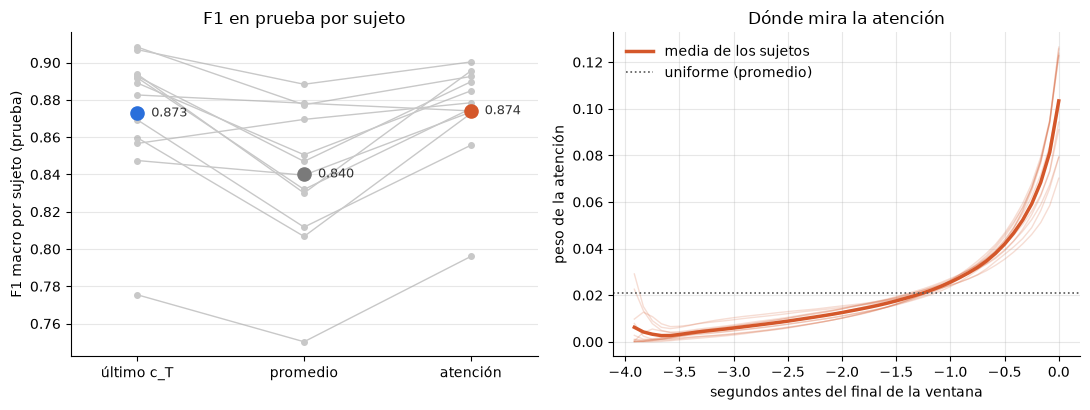

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# Izquierda: F1 en prueba de cada sujeto (líneas grises) y la media de cada variante
COLORS = {"ultimo": "#2a6fdb", "promedio": "#7a7a7a", "atencion": "#d4572a"}
ax = axes[0]
x = np.arange(len(POOLINGS))
per = np.array([results[p]["f1"] for p in POOLINGS])                       # (variantes, sujetos)
for j in range(per.shape[1]):
    ax.plot(x, per[:, j], color="#c8c8c8", lw=1, marker="o", ms=4, zorder=1)
for xi, p in zip(x, POOLINGS):
    m = per[xi].mean()
    ax.scatter(xi, m, s=90, color=COLORS[p], zorder=2)
    ax.annotate(f"{m:.3f}", (xi, m), xytext=(10, 0), textcoords="offset points", va="center", fontsize=9, color="#333")
ax.set_xticks(x, ["último c_T", "promedio", "atención"])
ax.set_xlim(-0.4, len(POOLINGS) - 0.6)
ax.set_ylabel("F1 macro por sujeto (prueba)")
ax.set_title("F1 en prueba por sujeto")
ax.grid(axis="y", alpha=0.3)

# Derecha: peso medio de la atención en cada instante (0 s = final de la ventana, el instante de la etiqueta)
ax = axes[1]
if "atencion" in POOLINGS:
    att = np.array([rounds[s]["atencion"]["atencion_media"] for s in FOLDS])  # (sujetos, 48)
    t = (np.arange(WIN) - (WIN - 1)) / TARGET_FS
    for row in att:
        ax.plot(t, row, color=COLORS["atencion"], alpha=0.2, lw=1)
    ax.plot(t, att.mean(0), color=COLORS["atencion"], lw=2.5, label="media de los sujetos")
    ax.axhline(1 / WIN, color="#555", ls=":", lw=1.2, label="uniforme (promedio)")
    ax.set_xlabel("segundos antes del final de la ventana")
    ax.set_ylabel("peso de la atención")
    ax.set_title("Dónde mira la atención")
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
    print(f"Peso de la atención en el último segundo (12 instantes): {att[:, -TARGET_FS:].sum(1).mean():.2f} "
          f"(uniforme: {TARGET_FS / WIN:.2f}); en el último instante: {att[:, -1].mean():.3f} (uniforme: {1 / WIN:.3f})")
plt.tight_layout()
plt.show()

# 7. Conclusiones

**Resumir toda la ventana no mejora al último instante.** La atención empata con `c_T`, y el promedio empeora de forma significativa. Se conserva el modelo del notebook 11: `c_T` con la cabeza lineal.

## Resultado

| Pooling | F1 prueba | Peor sujeto | Δ vs. último | Mejora en | p (Wilcoxon) | F1 entrenamiento |
|---|---|---|---|---|---|---|
| Último instante `c_T` (notebook 11) | **0.873** ± 0.036 | 0.775 | — | — | — | 0.897 |
| Promedio de `c_1 … c_T` | 0.840 ± 0.039 | 0.750 | **−0.033** | 1/12 | **0.002** | 0.876 |
| Atención sobre `c_1 … c_T` | **0.874** ± 0.027 | 0.796 | +0.001 | 5/12 | 0.97 | 0.901 |

Control: el modelo recargado reprodujo las predicciones del notebook 11.

## Por qué la atención no aporta

**1. Empata con el último instante en prueba y en entrenamiento.**
- En prueba, +0.001 (mejora en 5 de 12 sujetos, p = 0.97).
- En entrenamiento, +0.005 (p = 0.68).
- La diferencia de un sujeto a otro varía ± 0.015, quince veces más que la diferencia media.
- Las dos variantes coinciden en el 94.4 % de las ventanas. El 8.8 % lo fallan ambas, y solo un ≈ 2.6 % lo falla una sola.

**2. La atención aprendió a mirar el final de la ventana, es decir, a imitar `c_T`.**
Los pesos crecen hacia el final:

| Tramo de la ventana | Peso de la atención | Peso si fuera uniforme |
|---|---|---|
| Último segundo | 61 % | 25 % |
| Últimos 2 s | 84 % | 50 % |
| Primer segundo | 5 % | 25 % |
| Último instante | 10.3 % | 2.1 % (5 veces menos) |

Con libertad para usar cualquier parte de la ventana, la red eligió el final, donde está la etiqueta. Esto confirma que `c_T`, que además ya resume la historia de la ventana a través de la GRU, era la elección correcta.

**3. El promedio empeora porque mezcla la actividad anterior.**
- Baja el F1 en 11 de 12 sujetos (−0.033, p = 0.002).
- Baja en todas las clases salvo LF; las que más pierden son LT (−0.045), PT (−0.039), W (−0.038), K (−0.038) y PF (−0.043).
- También baja en entrenamiento (−0.021).

Al pesar igual los 48 instantes, el resumen se parece a lo que pasó antes de la etiqueta. Es la confirmación negativa del punto 2: lo que importa es el final de la ventana.

## Las ventanas casi siempre contienen más de una actividad

En los 12 sujetos evaluados, el **89.6 % de las ventanas cruza una transición**: alguno de sus 48 instantes tiene otra etiqueta u otro tramo sin etiqueta. No es un caso raro sino la norma, porque las actividades duran menos que la ventana. Medianas en los 507 ensayos:

| Actividad | LT | PT | LF | PF | W | N | K |
|---|---|---|---|---|---|---|---|
| Mediana de duración | 1.6 s | 2.2 s | 2.4 s | 2.8 s | 3.0 s | 3.7 s | 4.4 s |

El 15 % de los instantes no tiene etiqueta.

| Acierto | Último | Promedio | Atención |
|---|---|---|---|
| Ventanas sin transición (10.4 %) | 0.896 | 0.874 | **0.920** |
| Ventanas con transición (89.6 %) | 0.884 | 0.856 | 0.883 |

La atención solo gana en las ventanas sin transición, que son pocas y en su mayoría de actividades largas (N, K). En las que mezclan actividades, que son la mayoría y donde están los errores, empata con `c_T`. El efecto neto es nulo.

## Qué significa junto con el notebook 13

Ninguno de los dos cambios en la salida de la red mejora el desempeño:
- más capacidad en la cabeza (MLP, notebook 13): +0.003, p = 0.62;
- más información temporal antes de la cabeza (atención, este notebook): +0.001, p = 0.97.

Los errores, ≈ 9 % de las ventanas, se repiten con cualquier cabeza y cualquier pooling. El techo de ≈ 0.87–0.90, en prueba y en entrenamiento, **no está en cómo se lee la representación**. Está en la información de entrada y en la naturaleza de las etiquetas: acciones de 1.5–2.5 s (LT, PT, LF, PF) que con estas 10 variables se parecen entre sí y a N, como el propio artículo de referencia del dataset reporta para PT.

**Decisión:** se conserva `c_T` con la cabeza lineal. Es el modelo más simple y rinde igual que las alternativas.

Las palancas que quedan actúan sobre la entrada:
- **Información de carga (sEMG):** distingue colocar o levantar un objeto de estar quieto.
- **Más sujetos:** la mayor variación está entre personas (F1 de 0.78 a 0.91).
- **Ventana o etiquetado acordes a la duración de las acciones:** con acciones de ≈ 2 s, una ventana de 4 s siempre arrastra la actividad anterior.